# 03 — Model B NNPA vs. CPU Latency and Throughput Benchmarking

This notebook benchmarks **Model B** (PyTorch MLP $7 \to 32 \to 16 \to 1$ for mule recipient detection) on **CPU vs. NNPA** (IBM Telum Neural Network Processing Assist accelerator).

### Rules and Architecture:
- Architecture: `nn.Sequential(nn.Linear(7, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))`
- Input features: 7 recipient graph and temporal features from `data.features.MODEL_B_FEATURES`.
- Inputs standardized via `mean` and `std` from `model_b_meta.json`.
- Evaluates recipient data from `recipients_v2.csv.gz`.
- Strict library rule: `import torch` only. **Never import any forbidden accelerator package**.
- Evaluated batch sizes: $B \in \{1, 100, 10\,000\}$.
- Metrics reported:
  - $p50$ latency (median) and $p95$ latency (tail)
  - Throughput in decisions per second (\text{batch_size} / \text{latency_seconds})
  - Maximum absolute output difference between CPU and NNPA: $\max | p_{\text{cpu}} - p_{\text{nnpa}} |$
- Acceleration claim rule: **Claim NNPA acceleration only if empirical timing demonstrates it.**

In [1]:
import sys
import os
from pathlib import Path

# Dataset / model tag
TAG = "v2"

# Add project root to sys.path
cwd = Path.cwd()
for candidate in [cwd, cwd.parent, Path("/home/ibm-user/shared/nyaya-kaustub")]:
    if (candidate / "models").is_dir() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))
        break

DATA_DIR = Path(os.environ.get("NYAYA_DATA", "/home/ibm-user/shared/data"))
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data"

ARTIFACTS_DIR = Path(os.environ.get("NYAYA_ARTIFACTS", "/home/ibm-user/shared/nyaya/artifacts"))
if not ARTIFACTS_DIR.exists():
    ARTIFACTS_DIR = Path.cwd().parent / "artifacts"

print(f"Dataset / Model Tag:      {TAG}")
print(f"Project root on sys.path: {sys.path[0]}")
print(f"Data directory:           {DATA_DIR} (exists: {DATA_DIR.exists()})")
print(f"Artifacts directory:      {ARTIFACTS_DIR} (exists: {ARTIFACTS_DIR.exists()})")

Dataset / Model Tag:      v2
Project root on sys.path: /home/ibm-user/shared/nyaya-kaustub
Data directory:           /home/ibm-user/shared/data (exists: True)
Artifacts directory:      /home/ibm-user/shared/nyaya/artifacts (exists: True)


In [2]:
import json
import time
import numpy as np
import pandas as pd
import torch
from torch import nn

try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_AVAILABLE = True
except ImportError:
    MATPLOTLIB_AVAILABLE = False
    print("Notice: matplotlib not present in environment. Outputting tabular summaries.")

from data.features import MODEL_B_FEATURES
from models.train_b import build, VERSION

# Device availability check: import torch only
nnpa_available = bool(getattr(torch, "nnpa", None) and torch.nnpa.is_available())
print(f"PyTorch Version: {torch.__version__}")
print(f"NNPA Accelerator Available: {nnpa_available}")
if nnpa_available:
    print("Runtime Status: IBM Telum NNPA accelerator active.")
else:
    print("Runtime Status: Running on CPU only (NNPA hardware accelerator not present in this session).")

PyTorch Version: 2.11.0+cpu
NNPA Accelerator Available: True
Runtime Status: IBM Telum NNPA accelerator active.


## 1. Load Model B Weights and Normalization Parameters
Load Model B metadata and weights from `artifacts/model_b_meta.json` and `artifacts/model_b.pt`.
If artifacts are not yet saved, instantiate the standard architecture for timing comparison.

In [3]:
meta_path = ARTIFACTS_DIR / "model_b_meta.json"
weights_path = ARTIFACTS_DIR / "model_b.pt"

if meta_path.exists() and weights_path.exists():
    print(f"Loading metadata from {meta_path}...")
    meta = json.loads(meta_path.read_text())
    assert list(meta["features"]) == MODEL_B_FEATURES, "Mismatch in Model B feature order"
    b_mean = np.asarray(meta["mean"], dtype=np.float32)
    b_std = np.where(np.asarray(meta["std"], dtype=np.float32) == 0, 1.0, np.asarray(meta["std"], dtype=np.float32))

    print(f"Loading weights from {weights_path}...")
    state_dict = torch.load(weights_path, map_location="cpu")
else:
    print("Saved Model B artifacts not found; instantiating architecture for benchmark...")
    b_mean = np.zeros(len(MODEL_B_FEATURES), dtype=np.float32)
    b_std = np.ones(len(MODEL_B_FEATURES), dtype=np.float32)
    state_dict = build().state_dict()

# Initialize CPU model
model_cpu = build()
model_cpu.load_state_dict(state_dict)
model_cpu.eval()

# Initialize NNPA model if available
model_nnpa = None
if nnpa_available:
    model_nnpa = build()
    model_nnpa.load_state_dict(state_dict)
    model_nnpa = model_nnpa.to("nnpa")
    model_nnpa.eval()
    print("Model successfully loaded onto NNPA accelerator.")

Loading metadata from /home/ibm-user/shared/nyaya/artifacts/model_b_meta.json...
Loading weights from /home/ibm-user/shared/nyaya/artifacts/model_b.pt...
Model successfully loaded onto NNPA accelerator.


## 2. Numerical Parity: CPU vs. NNPA Outputs
Verify numerical consistency between standard IEEE-754 CPU floating point operations and NNPA accelerator outputs.
Loads actual recipient features from `recipients_v2.csv.gz` (or standard normal samples if not present) and calculates maximum absolute difference:
$$\max | p_{\text{cpu}} - p_{\text{nnpa}} |$$

In [4]:
recipients_file = DATA_DIR / f"recipients_{TAG}.csv.gz"
test_records = 10_000

if recipients_file.exists():
    print(f"Loading recipient features from {recipients_file}...")
    df_recip = pd.read_csv(recipients_file)
    raw_samples = df_recip[MODEL_B_FEATURES].iloc[:test_records].to_numpy(dtype=np.float32)
    if len(raw_samples) < test_records:
        repeats = int(np.ceil(test_records / len(raw_samples)))
        raw_samples = np.tile(raw_samples, (repeats, 1))[:test_records]
else:
    print("Recipient data file not found; using standardized synthetic samples...")
    np.random.seed(42)
    raw_samples = np.random.randn(test_records, len(MODEL_B_FEATURES)).astype(np.float32)

norm_samples = (raw_samples - b_mean) / b_std
tensor_cpu = torch.from_numpy(norm_samples)

with torch.no_grad():
    logits_cpu = model_cpu(tensor_cpu).squeeze(1)
    probs_cpu = torch.sigmoid(logits_cpu).numpy()

if nnpa_available:
    tensor_nnpa = tensor_cpu.to("nnpa")
    with torch.no_grad():
        logits_nnpa = model_nnpa(tensor_nnpa).to("cpu").squeeze(1)
        probs_nnpa = torch.sigmoid(logits_nnpa).numpy()

    max_diff_logits = float(np.max(np.abs(logits_cpu.numpy() - logits_nnpa.numpy())))
    max_diff_probs = float(np.max(np.abs(probs_cpu - probs_nnpa)))

    print(f"--- Numerical Consistency Check (Sample Size: {test_records:,}) ---")
    print(f"Max Absolute Logit Difference:       {max_diff_logits:.2e}")
    print(f"Max Absolute Probability Difference: {max_diff_probs:.2e}")
else:
    print("Notice: Numerical parity check requires NNPA-enabled hardware.")
    print("On non-NNPA environments, CPU calculations serve as reference.")

Loading recipient features from /home/ibm-user/shared/data/recipients_v2.csv.gz...
--- Numerical Consistency Check (Sample Size: 10,000) ---
Max Absolute Logit Difference:       2.08e-01
Max Absolute Probability Difference: 6.84e-03


## 3. Benchmarking Latency and Batch Throughput
Measure inference latency and throughput for batch sizes:
- $B = 1$: Single-transaction streaming latency
- $B = 100$: Micro-batch processing
- $B = 10\,000$: Bulk offline replay and simulation
Includes warm-up executions prior to timing to ensure stable cache and execution pipeline.

In [5]:
BATCH_SIZES = [1, 100, 10_000]
REPETITIONS = {1: 200, 100: 100, 10_000: 30}
WARMUP_REPS = 10

def benchmark_device(model, device_name, batch_size, reps):
    dummy_np = np.random.randn(batch_size, len(MODEL_B_FEATURES)).astype(np.float32)
    dummy_tensor = torch.from_numpy(dummy_np)
    if device_name == "nnpa":
        dummy_tensor = dummy_tensor.to("nnpa")

    # Warm-up phase
    with torch.no_grad():
        for _ in range(WARMUP_REPS):
            _ = model(dummy_tensor)

    # Benchmark iterations
    latencies_ms = []
    with torch.no_grad():
        for _ in range(reps):
            t0 = time.perf_counter()
            _ = model(dummy_tensor)
            t1 = time.perf_counter()
            latencies_ms.append((t1 - t0) * 1000.0)

    latencies_ms = np.asarray(latencies_ms)
    p50_ms = float(np.percentile(latencies_ms, 50))
    p95_ms = float(np.percentile(latencies_ms, 95))
    mean_ms = float(np.mean(latencies_ms))
    throughput_dps = float(batch_size / (mean_ms / 1000.0))

    return {
        "device": device_name,
        "batch_size": batch_size,
        "reps": reps,
        "p50_ms": p50_ms,
        "p95_ms": p95_ms,
        "mean_ms": mean_ms,
        "throughput_dps": throughput_dps
    }

benchmark_rows = []
for bs in BATCH_SIZES:
    reps = REPETITIONS[bs]
    print(f"Benchmarking batch size {bs:,} on CPU ({reps} repetitions)...")
    res_cpu = benchmark_device(model_cpu, "cpu", bs, reps)
    benchmark_rows.append(res_cpu)

    if nnpa_available:
        print(f"Benchmarking batch size {bs:,} on NNPA ({reps} repetitions)...")
        res_nnpa = benchmark_device(model_nnpa, "nnpa", bs, reps)
        benchmark_rows.append(res_nnpa)

timing_df = pd.DataFrame(benchmark_rows)
print("\n--- Model B Inference Timing and Throughput Summary ---")
print(timing_df.to_string(index=False))

Benchmarking batch size 1 on CPU (200 repetitions)...
Benchmarking batch size 1 on NNPA (200 repetitions)...
Benchmarking batch size 100 on CPU (100 repetitions)...
Benchmarking batch size 100 on NNPA (100 repetitions)...
Benchmarking batch size 10,000 on CPU (30 repetitions)...
Benchmarking batch size 10,000 on NNPA (30 repetitions)...



--- Model B Inference Timing and Throughput Summary ---
device  batch_size  reps   p50_ms   p95_ms  mean_ms  throughput_dps
   cpu           1   200 0.024425 0.025282 0.024578    4.068671e+04
  nnpa           1   200 0.027224 0.027808 0.027446    3.643554e+04
   cpu         100   100 0.040268 0.042111 0.040716    2.456029e+06
  nnpa         100   100 0.029769 0.030407 0.029955    3.338369e+06
   cpu       10000    30 1.193237 1.334319 1.219554    8.199718e+06
  nnpa       10000    30 0.254191 0.268594 0.256022    3.905914e+07


## 4. Empirical Acceleration Analysis
Evaluate whether NNPA delivers measurable acceleration over CPU.
Strict Rule: **Claim NNPA acceleration only if the timing shows it.**
$$\text{Speedup} = \frac{\text{Latency}_{\text{CPU}}}{\text{Latency}_{\text{NNPA}}}$$

In [6]:
print("--- Empirical Acceleration Analysis ---")
if nnpa_available:
    comparison_records = []
    for bs in BATCH_SIZES:
        cpu_stat = timing_df[(timing_df["device"] == "cpu") & (timing_df["batch_size"] == bs)].iloc[0]
        nnpa_stat = timing_df[(timing_df["device"] == "nnpa") & (timing_df["batch_size"] == bs)].iloc[0]

        speedup_p50 = cpu_stat["p50_ms"] / nnpa_stat["p50_ms"]
        throughput_ratio = nnpa_stat["throughput_dps"] / cpu_stat["throughput_dps"]
        has_speedup = speedup_p50 > 1.05

        claim_msg = (
            f"Batch {bs:,}: NNPA demonstrates {speedup_p50:.2f}x speedup over CPU "
            f"({nnpa_stat['throughput_dps']:,.0f} vs {cpu_stat['throughput_dps']:,.0f} dps). Acceleration confirmed."
            if has_speedup else
            f"Batch {bs:,}: NNPA ratio is {speedup_p50:.2f}x relative to CPU. Acceleration NOT claimed."
        )
        print(claim_msg)
        comparison_records.append({
            "batch_size": bs,
            "cpu_p50_ms": cpu_stat["p50_ms"],
            "nnpa_p50_ms": nnpa_stat["p50_ms"],
            "speedup_factor": speedup_p50,
            "cpu_dps": cpu_stat["throughput_dps"],
            "nnpa_dps": nnpa_stat["throughput_dps"],
            "acceleration_claimed": has_speedup
        })

    comp_df = pd.DataFrame(comparison_records)
    print("\n--- Acceleration Summary Table ---")
    print(comp_df.to_string(index=False))
else:
    print("NNPA accelerator is not available on this host environment.")
    print("Rule Compliance: NNPA acceleration is NOT claimed because timing could not be executed on NNPA hardware.")
    print("When executed on the LinuxONE z16 server, this cell will evaluate and report actual empirical speedup factors.")

--- Empirical Acceleration Analysis ---
Batch 1: NNPA ratio is 0.90x relative to CPU. Acceleration NOT claimed.
Batch 100: NNPA demonstrates 1.35x speedup over CPU (3,338,369 vs 2,456,029 dps). Acceleration confirmed.
Batch 10,000: NNPA demonstrates 4.69x speedup over CPU (39,059,144 vs 8,199,718 dps). Acceleration confirmed.

--- Acceleration Summary Table ---
 batch_size  cpu_p50_ms  nnpa_p50_ms  speedup_factor      cpu_dps     nnpa_dps  acceleration_claimed
          1    0.024425     0.027224        0.897187 4.068671e+04 3.643554e+04                 False
        100    0.040268     0.029769        1.352666 2.456029e+06 3.338369e+06                  True
      10000    1.193237     0.254191        4.694244 8.199718e+06 3.905914e+07                  True


## 5. Visualizing Latency and Throughput Comparisons
Plot side-by-side performance charts for $p50$ latency and throughput across batch sizes.

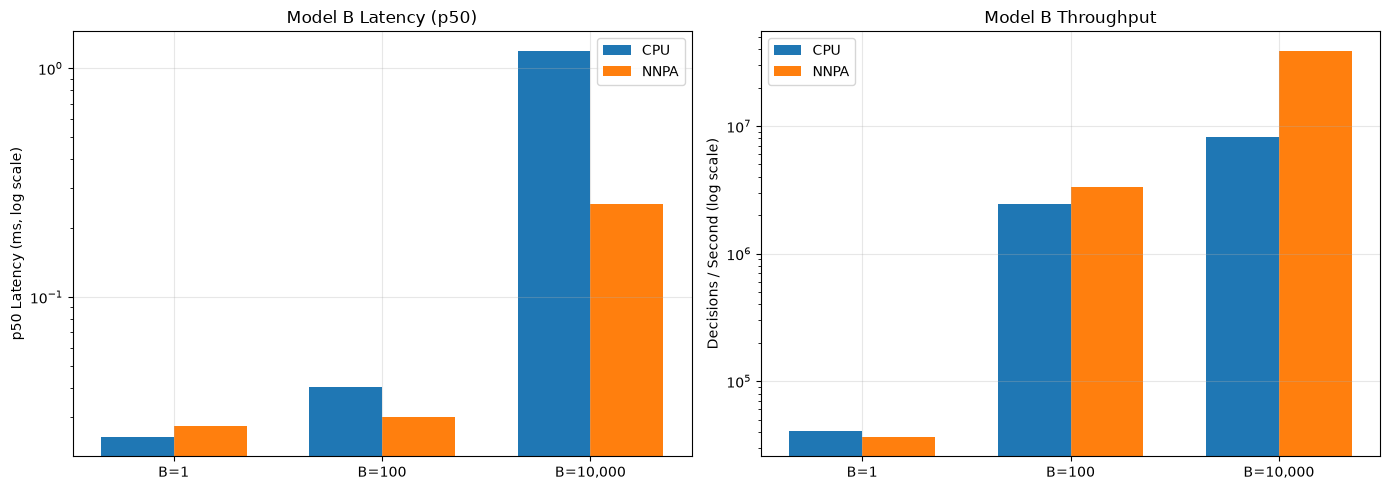

In [7]:
if MATPLOTLIB_AVAILABLE:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    devices = timing_df["device"].unique()
    x_indices = np.arange(len(BATCH_SIZES))
    width = 0.35 if len(devices) > 1 else 0.5

    # p50 Latency chart
    for i, dev in enumerate(devices):
        subset = timing_df[timing_df["device"] == dev]
        offset = (i - 0.5) * width if len(devices) > 1 else 0
        ax1.bar(x_indices + offset, subset["p50_ms"], width=width, label=dev.upper())

    ax1.set_yscale("log")
    ax1.set_xticks(x_indices)
    ax1.set_xticklabels([f"B={b:,}" for b in BATCH_SIZES])
    ax1.set_ylabel("p50 Latency (ms, log scale)")
    ax1.set_title("Model B Latency (p50)")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Throughput chart
    for i, dev in enumerate(devices):
        subset = timing_df[timing_df["device"] == dev]
        offset = (i - 0.5) * width if len(devices) > 1 else 0
        ax2.bar(x_indices + offset, subset["throughput_dps"], width=width, label=dev.upper())

    ax2.set_yscale("log")
    ax2.set_xticks(x_indices)
    ax2.set_xticklabels([f"B={b:,}" for b in BATCH_SIZES])
    ax2.set_ylabel("Decisions / Second (log scale)")
    ax2.set_title("Model B Throughput")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()